# MScFE 690 Capstone: CVaR-Constrained XGBoost Portfolio with Transaction Costs


# Study Extension

This notebook extends the existing XGBoost portfolio baseline by adding:

- a **95% historical CVaR constraint**, and
- proportional **transaction costs based on portfolio turnover**.

The forecasting model is kept unchanged. The main comparison is therefore between:

1. an unconstrained XGBoost portfolio, and  
2. an otherwise identical XGBoost portfolio with an additional CVaR constraint.

Both portfolios are long-only, fully invested and subject to a 30% maximum weight per asset.

The portfolio objective is:

$$
\max_w \quad \hat{\mu}_t^\top w
-\lambda w^\top \Sigma_t w
-\gamma \|w-w_{t-1}\|_1.
$$

For the CVaR portfolio, the additional restriction is:

$$
\operatorname{CVaR}_{0.95}(L_t(w)) \leq C.
$$

Transaction costs are modelled as:

$$
\operatorname{Cost}_t
=
c \sum_i |w_{i,t}-w_{i,t-1}|,
$$

with a 10 bps base case and 5/20 bps sensitivity checks.

**References:**  
Rockafellar, R. T. and Uryasev, S. (2000), *Optimization of Conditional Value-at-Risk*.  
Chen, T. and Guestrin, C. (2016), *XGBoost: A Scalable Tree Boosting System*.


In [1]:
%pip install -q yfinance==1.2.0 cvxpy openpyxl xgboost


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import cvxpy as cp
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 150)


## 1. Configuration

Yahoo Finance treats the `end` date as exclusive, so `2026-01-01` is used to include observations through `2025-12-31`.

The model configuration and feature definitions match the previous XGBoost baseline notebook. Portfolio-specific parameters are defined separately so they can be reviewed and adjusted without changing the forecasting model.


In [3]:
TICKERS = ["SPY", "EFA", "EEM", "IEF", "TLT", "LQD", "GLD", "DBC"]

START_DATE = "2010-01-01"
END_DATE = "2026-01-01"

TRAIN_END = "2016-12-31"
VALID_START = "2017-01-01"
VALID_END = "2018-12-31"
TEST_START = "2019-01-01"

MAX_WEIGHT = 0.30
LOOKBACK_DAYS = 252
WEEKLY_RULE = "W-FRI"
FORECAST_HORIZON = 5

# Portfolio parameters
# Portfolio parameters are selected using the validation period
RISK_AVERSION_GRID = [2.5, 5.0, 10.0, 20.0]
TURNOVER_PENALTY_GRID = [0.0, 0.001, 0.0025, 0.005]

# CVaR specification
CVAR_CONFIDENCE = 0.95

# Transaction-cost specification
BASE_COST_BPS = 10
COST_SENSITIVITY_BPS = [5, 10, 20]

BASE = Path(".")
for p in [
    BASE / "data" / "raw",
    BASE / "data" / "processed",
    BASE / "data" / "validation",
    BASE / "outputs" / "cvar",
    BASE / "outputs" / "figures",
]:
    p.mkdir(parents=True, exist_ok=True)

print("Folders ready.")


Folders ready.


## 2. Download Daily Yahoo Finance Data


In [4]:
raw = yf.download(
    TICKERS,
    start=START_DATE,
    end=END_DATE,
    progress=False,
    auto_adjust=False,
    threads=False,
)[["Adj Close", "Volume"]]

print("Raw shape:", raw.shape)
display(raw.head())


Raw shape: (4024, 16)


Price       Adj Close                                                                                 Volume                                         \
Ticker            DBC        EEM        EFA         GLD        IEF        LQD        SPY        TLT      DBC       EEM       EFA       GLD      IEF   
Date                                                                                                                                                  
2010-01-04  21.338846  30.194561  34.581203  109.800003  60.504982  56.502216  84.368950  54.849937  2046900  70761600  18556900  16224100   619100   
2010-01-05  21.364210  30.413725  34.611691  109.699997  60.770630  56.772060  84.592331  55.204170  2335400  50196300  14352800  14213100  1547500   
2010-01-06  21.744654  30.477354  34.757984  111.510002  60.525421  56.604782  84.651871  54.465122  2262600  50670000  11888100  24981900   365500   
2010-01-07  21.474115  30.300606  34.623871  110.820000  60.525421  56.674961  85.009193  54.556713  1604100  41803700  10906600  13609800   390900   
2010-01-08  21.457205  30.540970  34.898190  111.370003  60.600403  56.799076  85.292091  54.532330  1565300  41118100  12826500  15894600   382500   

Price                                    
Ticker          LQD        SPY      TLT  
Date                                     
2010-01-04  2017600  118944600  2829100  
2010-01-05  1143800  111579900  2841600  
2010-01-06  1005500  116074400  4099600  
2010-01-07  1264100  131091100  2793200  
2010-01-08   704600  126402800  2910700

In [5]:
raw.to_csv(BASE / "data" / "raw" / "yahoo_etf_raw.csv")
print("Saved raw Yahoo Finance data.")


Saved raw Yahoo Finance data.


## 3. Extract Adjusted Close Prices and Volume

Adjusted close prices are used for return calculations because they account for distributions and corporate actions. Trading volume is retained because it is part of the existing XGBoost feature set.


In [6]:
adjusted_close = raw["Adj Close"].reindex(columns=TICKERS).sort_index()
adjusted_close.index = pd.to_datetime(adjusted_close.index)

volume = raw["Volume"].reindex(columns=TICKERS).sort_index()
volume.index = pd.to_datetime(volume.index)
volume = volume.reindex(adjusted_close.index)

display(adjusted_close.head())
display(volume.head())


Ticker,SPY,EFA,EEM,IEF,TLT,LQD,GLD,DBC
Date,,,,,,,,
2010-01-04,84.368950,34.581203,30.194561,60.504982,54.849937,56.502216,109.800003,21.338846
2010-01-05,84.592331,34.611691,30.413725,60.770630,55.204170,56.772060,109.699997,21.364210
2010-01-06,84.651871,34.757984,30.477354,60.525421,54.465122,56.604782,111.510002,21.744654
2010-01-07,85.009193,34.623871,30.300606,60.525421,54.556713,56.674961,110.820000,21.474115
2010-01-08,85.292091,34.898190,30.540970,60.600403,54.532330,56.799076,111.370003,21.457205


Ticker,SPY,EFA,EEM,IEF,TLT,LQD,GLD,DBC
Date,,,,,,,,
2010-01-04,118944600,18556900,70761600,619100,2829100,2017600,16224100,2046900
2010-01-05,111579900,14352800,50196300,1547500,2841600,1143800,14213100,2335400
2010-01-06,116074400,11888100,50670000,365500,4099600,1005500,24981900,2262600
2010-01-07,131091100,10906600,41803700,390900,2793200,1264100,13609800,1604100
2010-01-08,126402800,12826500,41118100,382500,2910700,704600,15894600,1565300


## 4. Data Validation

The validation checks are retained from the baseline notebook so that the CVaR experiment uses the same clean investment universe.


In [7]:
validation_rows = []

for ticker in TICKERS:
    s = adjusted_close[ticker]
    validation_rows.append({
        "Ticker": ticker,
        "First_Valid_Date": s.first_valid_index(),
        "Last_Valid_Date": s.last_valid_index(),
        "Observations": int(s.notna().sum()),
        "Missing_Values": int(s.isna().sum()),
        "Non_Positive_Prices": int((s.dropna() <= 0).sum()),
    })

quality_report = pd.DataFrame(validation_rows)
duplicate_dates = int(adjusted_close.index.duplicated().sum())

diagnostic_returns = adjusted_close.pct_change(fill_method=None)

extreme_return_report = pd.DataFrame({
    "Ticker": TICKERS,
    "Min_Daily_Return": [diagnostic_returns[t].min() for t in TICKERS],
    "Max_Daily_Return": [diagnostic_returns[t].max() for t in TICKERS],
    "Abs_Return_Above_20pct": [(diagnostic_returns[t].abs() > 0.20).sum() for t in TICKERS],
})

quality_report = quality_report.merge(extreme_return_report, on="Ticker", how="left")
quality_report["Duplicate_Dates_In_Index"] = duplicate_dates

display(quality_report)
quality_report.to_csv(BASE / "data" / "validation" / "data_quality_report.csv", index=False)


,Ticker,First_Valid_Date,Last_Valid_Date,Observations,Missing_Values,Non_Positive_Prices,Min_Daily_Return,Max_Daily_Return,Abs_Return_Above_20pct,Duplicate_Dates_In_Index
0,SPY,2010-01-04,2025-12-31,4024,0,0,-0.109424,0.105019,0,0
1,EFA,2010-01-04,2025-12-31,4024,0,0,-0.109902,0.084731,0,0
2,EEM,2010-01-04,2025-12-31,4024,0,0,-0.124793,0.080529,0,0
3,IEF,2010-01-04,2025-12-31,4024,0,0,-0.025072,0.026416,0,0
4,TLT,2010-01-04,2025-12-31,4024,0,0,-0.066683,0.075195,0,0
5,LQD,2010-01-04,2025-12-31,4024,0,0,-0.050030,0.073918,0,0
6,GLD,2010-01-04,2025-12-31,4024,0,0,-0.087808,0.049038,0,0
7,DBC,2010-01-04,2025-12-31,4024,0,0,-0.079444,0.047990,0,0


## 5. Align the Investment Universe

Only dates where all eight ETFs have valid adjusted prices are retained. Volume is aligned to the same dates.


In [8]:
prices_aligned = adjusted_close.dropna(how="any").copy()
volume_aligned = volume.reindex(prices_aligned.index).copy()

print("Before alignment:", adjusted_close.shape)
print("After alignment :", prices_aligned.shape)
print("Start:", prices_aligned.index.min())
print("End  :", prices_aligned.index.max())

prices_aligned.to_csv(BASE / "data" / "processed" / "adjusted_close.csv")
volume_aligned.to_csv(BASE / "data" / "processed" / "volume.csv")


Before alignment: (4024, 8)
After alignment : (4024, 8)
Start: 2010-01-04 00:00:00
End  : 2025-12-31 00:00:00


## 6. Daily Simple Returns and Log Returns


In [9]:
daily_returns = prices_aligned.pct_change(fill_method=None).dropna()
log_returns = np.log(prices_aligned / prices_aligned.shift(1)).dropna()

daily_returns.to_csv(BASE / "data" / "processed" / "daily_returns.csv")
log_returns.to_csv(BASE / "data" / "processed" / "log_returns.csv")

display(daily_returns.head())


Ticker,SPY,EFA,EEM,IEF,TLT,LQD,GLD,DBC
Date,,,,,,,,
2010-01-05,0.002648,0.000882,0.007258,0.004391,0.006458,0.004776,-0.000911,0.001189
2010-01-06,0.000704,0.004227,0.002092,-0.004035,-0.013388,-0.002946,0.016500,0.017808
2010-01-07,0.004221,-0.003858,-0.005799,0.000000,0.001682,0.001240,-0.006188,-0.012442
2010-01-08,0.003328,0.007923,0.007933,0.001239,-0.000447,0.002190,0.004963,-0.000787
2010-01-11,0.001397,0.008210,-0.002083,0.000674,-0.005488,0.001045,0.013289,-0.003152


## 7. Five-Trading-Day Forward Return Target

For asset $i$ at time $t$:

$$
R_{i,t \rightarrow t+5} = \frac{P_{i,t+5}}{P_{i,t}} - 1.
$$

This is the same forward-looking target used in the baseline XGBoost notebook.


In [10]:
forward_5d_returns = prices_aligned.shift(-5) / prices_aligned - 1
forward_5d_returns.to_csv(BASE / "data" / "processed" / "forward_5d_returns.csv")

display(forward_5d_returns.head())


Ticker,SPY,EFA,EEM,IEF,TLT,LQD,GLD,DBC
Date,,,,,,,,
2010-01-04,0.012354,0.017451,0.009366,0.002252,-0.011246,0.006304,0.027778,0.002377
2010-01-05,0.000264,0.004579,-0.013947,0.005045,-0.000775,0.003422,0.007201,-0.020182
2010-01-06,0.008003,0.008769,-0.012990,0.004277,0.001010,0.002193,0.000269,-0.036547
2010-01-07,0.006481,0.020423,-0.009799,0.009004,0.013322,0.004570,0.010919,-0.029528
2010-01-08,-0.008117,-0.003494,-0.028935,0.012252,0.020047,0.001995,-0.004579,-0.039795


## 8. Research Period Labels


In [11]:
calendar = pd.DataFrame(index=prices_aligned.index)

calendar["Period"] = np.select(
    [
        calendar.index <= pd.Timestamp(TRAIN_END),
        (calendar.index >= pd.Timestamp(VALID_START)) & (calendar.index <= pd.Timestamp(VALID_END)),
        calendar.index >= pd.Timestamp(TEST_START),
    ],
    ["Train", "Validation", "Test"],
    default="Outside"
)

display(calendar["Period"].value_counts())


Period
Train         1762
Test          1760
Validation     502
Name: count, dtype: int64

## 9. Five-Trading-Day Purge at Sample Boundaries

Because the target uses the next five trading days, the final five trading observations immediately before the validation and test periods are excluded from model fitting.


In [12]:
calendar["Purged"] = False

valid_start_actual = calendar.index[calendar.index >= pd.Timestamp(VALID_START)][0]
test_start_actual = calendar.index[calendar.index >= pd.Timestamp(TEST_START)][0]

before_valid = calendar.index[calendar.index < valid_start_actual][-5:]
before_test = calendar.index[calendar.index < test_start_actual][-5:]

calendar.loc[before_valid, "Purged"] = True
calendar.loc[before_test, "Purged"] = True
calendar["Usable_For_Model"] = ~calendar["Purged"]

print("Validation starts:", valid_start_actual)
print("Test starts      :", test_start_actual)

calendar.to_csv(BASE / "data" / "processed" / "modelling_calendar.csv")


Validation starts: 2017-01-03 00:00:00
Test starts      : 2019-01-02 00:00:00


# 10. Feature Construction for XGBoost

To preserve comparability with the baseline notebook, the XGBoost model uses the same five predictors:

1. 5-day return
2. 20-day return
3. 20-day realised volatility
4. Price relative to the 20-day moving average
5. 5-day percentage change in trading volume

No forecasting feature is changed in the CVaR experiment.


In [13]:
FEATURE_NAMES = [
    "Return_5D",
    "Return_20D",
    "Volatility_20D",
    "Price_MA20_Gap",
    "Volume_Change_5D",
]

def build_features(prices, volume):
    daily_ret = prices.pct_change(fill_method=None)
    features = {}

    for ticker in TICKERS:
        p = prices[ticker]
        v = volume[ticker]
        r = daily_ret[ticker]

        df = pd.DataFrame(index=prices.index)
        df["Return_5D"] = p.pct_change(5)
        df["Return_20D"] = p.pct_change(20)
        df["Volatility_20D"] = r.rolling(20).std()
        df["Price_MA20_Gap"] = p / p.rolling(20).mean() - 1
        df["Volume_Change_5D"] = v.pct_change(5).replace([np.inf, -np.inf], np.nan)

        features[ticker] = df

    return features

feature_data = build_features(prices_aligned, volume_aligned)
display(feature_data["SPY"].head(25))


,Return_5D,Return_20D,Volatility_20D,Price_MA20_Gap,Volume_Change_5D
Date,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN
2010-01-05,NaN,NaN,NaN,NaN,NaN
2010-01-06,NaN,NaN,NaN,NaN,NaN
2010-01-07,NaN,NaN,NaN,NaN,NaN
2010-01-08,NaN,NaN,NaN,NaN,NaN
2010-01-11,0.012354,NaN,NaN,NaN,-0.105670
2010-01-12,0.000264,NaN,NaN,NaN,0.463825
2010-01-13,0.008003,NaN,NaN,NaN,0.394123
2010-01-14,0.006481,NaN,NaN,NaN,-0.117264


## 10.1 Build Asset-Level Modelling Dataset


In [14]:
model_data = {}

for ticker in TICKERS:
    df = feature_data[ticker].copy()
    df["Target"] = forward_5d_returns[ticker]
    df["Period"] = calendar["Period"]
    df["Purged"] = calendar["Purged"]
    df = df.dropna(subset=FEATURE_NAMES + ["Target"])
    model_data[ticker] = df

display(model_data["SPY"].head())
print("SPY observations:", len(model_data["SPY"]))


,Return_5D,Return_20D,Volatility_20D,Price_MA20_Gap,Volume_Change_5D,Target,Period,Purged
Date,,,,,,,,
2010-02-02,0.009789,-0.026030,0.010585,-0.015277,0.024431,-0.028628,Train,False
2010-02-03,0.000000,-0.033442,0.010574,-0.018521,-0.364642,-0.025676,Train,False
2010-02-04,-0.019619,-0.063935,0.012403,-0.045715,0.128476,0.015877,Train,False
2010-02-05,-0.006798,-0.065943,0.012344,-0.040504,0.588740,0.012938,Train,False
2010-02-08,-0.029067,-0.075762,0.012270,-0.043697,0.193234,0.036359,Train,False


SPY observations: 3999


## 10.2 XGBoost Model Configuration


In [15]:
def make_xgb_model():
    return XGBRegressor(
        objective="reg:squarederror",
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.80,
        colsample_bytree=0.80,
        min_child_weight=5,
        reg_alpha=0.10,
        reg_lambda=1.00,
        random_state=42,
        n_jobs=-1,
    )


## 10.3 Validation Performance

The model specification is unchanged from the existing baseline. The test period remains untouched during model selection.


In [16]:
validation_results = []

for ticker in TICKERS:
    df = model_data[ticker]

    train = df[(df["Period"] == "Train") & (~df["Purged"])]
    valid = df[(df["Period"] == "Validation") & (~df["Purged"])]

    model = make_xgb_model()
    model.fit(train[FEATURE_NAMES], train["Target"], verbose=False)

    pred = model.predict(valid[FEATURE_NAMES])
    actual = valid["Target"].values

    validation_results.append({
        "Ticker": ticker,
        "Validation_RMSE": np.sqrt(np.mean((actual - pred) ** 2)),
        "Validation_MAE": np.mean(np.abs(actual - pred)),
        "Validation_Correlation": np.corrcoef(actual, pred)[0, 1] if len(valid) > 1 else np.nan,
    })

validation_metrics = pd.DataFrame(validation_results).set_index("Ticker")
display(validation_metrics)

validation_metrics.to_csv(
    BASE / "outputs" / "cvar" / "xgb_validation_metrics.csv"
)


,Validation_RMSE,Validation_MAE,Validation_Correlation
Ticker,,,
SPY,0.019573,0.013089,-0.131883
EFA,0.016720,0.012709,0.046120
EEM,0.023224,0.018019,0.170288
IEF,0.005883,0.004702,0.110264
TLT,0.013468,0.010996,0.009856
LQD,0.005965,0.004742,-0.029698
GLD,0.016346,0.013333,0.087231
DBC,0.020480,0.016501,-0.062090


## 11. Weekly Portfolio Rebalance Dataset

The underlying information remains daily, while portfolio decisions and holdings are updated weekly.


In [17]:
weekly_prices = prices_aligned.resample(WEEKLY_RULE).last().dropna()
weekly_returns = weekly_prices.pct_change(fill_method=None).dropna()

weekly_prices.to_csv(BASE / "data" / "processed" / "weekly_prices.csv")
weekly_returns.to_csv(BASE / "data" / "processed" / "weekly_returns.csv")

print("Weekly prices:", weekly_prices.shape)
display(weekly_prices.head())


Weekly prices: (835, 8)


Ticker,SPY,EFA,EEM,IEF,TLT,LQD,GLD,DBC
Date,,,,,,,,
2010-01-08,85.292091,34.898190,30.540970,60.600403,54.532330,56.799076,111.370003,21.457205
2010-01-15,84.599739,34.776272,29.657267,61.342850,55.625549,56.912399,110.860001,20.603313
2010-01-22,81.301842,32.837822,28.002968,61.724346,56.187424,56.987904,107.169998,19.884691
2010-01-29,79.946915,31.990507,27.062704,61.785652,56.376728,56.907021,105.959999,19.182981
2010-02-05,79.403473,31.380939,26.299175,62.086369,56.373669,56.593700,104.680000,18.920893


# 12. Walk-Forward XGBoost Return Forecasts

For each weekly decision date in the test period, the model is refitted using only information available before the decision date. The same five-trading-day purge used in the baseline is retained.


In [18]:
test_dates = weekly_prices.index[weekly_prices.index >= pd.Timestamp(TEST_START)]
trading_dates = prices_aligned.index

xgb_forecasts = pd.DataFrame(
    np.nan,
    columns=TICKERS,
    index=pd.Index(test_dates[:-1], name="Decision_Date")
)

xgb_actual_returns = xgb_forecasts.copy()
metadata_rows = []

for decision_date, return_date in zip(test_dates[:-1], test_dates[1:]):
    position = trading_dates.searchsorted(decision_date, side="right") - 1
    feature_date = trading_dates[position]

    # Exclude observations whose 5-day target can overlap the decision date
    train_end_date = trading_dates[position - 5]

    for ticker in TICKERS:
        df = model_data[ticker]
        train_df = df[
            (df.index <= train_end_date)
            & (~df["Purged"])
            & (df["Target"].notna())
        ]

        if len(train_df) < 250:
            continue

        model = make_xgb_model()
        model.fit(train_df[FEATURE_NAMES], train_df["Target"], verbose=False)

        feature_row = feature_data[ticker].loc[[feature_date], FEATURE_NAMES]

        xgb_forecasts.loc[decision_date, ticker] = float(model.predict(feature_row)[0])
        xgb_actual_returns.loc[decision_date, ticker] = forward_5d_returns.loc[feature_date, ticker]

    metadata_rows.append((decision_date, feature_date, return_date))

xgb_forecast_metadata = pd.DataFrame(
    metadata_rows,
    columns=["Decision_Date", "Feature_Date", "Return_Date"]
).set_index("Decision_Date")

display(xgb_forecasts.head())
display(xgb_forecast_metadata.head())


,SPY,EFA,EEM,IEF,TLT,LQD,GLD,DBC
Decision_Date,,,,,,,,
2019-01-04,0.005102,-0.001331,-0.003114,-0.000038,-0.001858,0.000449,0.005109,0.011385
2019-01-11,-0.010323,0.001314,0.000721,0.001967,0.007480,-0.001535,0.000309,-0.000403
2019-01-18,-0.005277,-0.000287,-0.003601,0.002314,-0.001117,-0.000213,-0.000508,-0.009052
2019-01-25,0.011107,0.001586,0.000646,0.002085,0.002516,0.000336,0.001245,0.001955
2019-02-01,0.008077,-0.000491,0.001553,0.000630,0.000447,0.002373,0.001466,0.000427


,Feature_Date,Return_Date
Decision_Date,,
2019-01-04,2019-01-04,2019-01-11
2019-01-11,2019-01-11,2019-01-18
2019-01-18,2019-01-18,2019-01-25
2019-01-25,2019-01-25,2019-02-01
2019-02-01,2019-02-01,2019-02-08


## 12.1 Forecast Diagnostics


In [19]:
forecast_metrics = pd.DataFrame(
    index=TICKERS,
    columns=["RMSE", "MAE", "Correlation"],
    dtype=float
)

for ticker in TICKERS:
    a = xgb_actual_returns[ticker].dropna()
    p = xgb_forecasts.loc[a.index, ticker].dropna()

    common = a.index.intersection(p.index)
    a = a.loc[common]
    p = p.loc[common]

    forecast_metrics.loc[ticker, "RMSE"] = np.sqrt(np.mean((a - p) ** 2))
    forecast_metrics.loc[ticker, "MAE"] = np.mean(np.abs(a - p))
    forecast_metrics.loc[ticker, "Correlation"] = (
        np.corrcoef(a, p)[0, 1] if len(common) > 1 else np.nan
    )

display(forecast_metrics)

xgb_forecasts.to_csv(BASE / "outputs" / "cvar" / "xgb_test_forecasts.csv")
xgb_forecast_metadata.to_csv(BASE / "outputs" / "cvar" / "xgb_test_forecast_metadata.csv")
forecast_metrics.to_csv(BASE / "outputs" / "cvar" / "xgb_test_forecast_metrics.csv")


,RMSE,MAE,Correlation
SPY,0.027876,0.018782,-0.146621
EFA,0.027989,0.018870,-0.193538
EEM,0.027970,0.020791,0.033297
IEF,0.009900,0.007531,0.031898
TLT,0.022336,0.017301,0.033521
LQD,0.018191,0.009897,-0.179944
GLD,0.021950,0.016398,0.087234
DBC,0.027166,0.020225,0.010808


# 13. Historical Five-Day Scenarios for CVaR

The CVaR constraint is estimated from **historical joint asset-return scenarios**.

At each decision date:

1. Take the trailing 252 daily observations.
2. Convert them into overlapping historical five-trading-day returns.
3. Treat each row as one joint return scenario across the eight ETFs.
4. Compute portfolio loss as the negative of the scenario portfolio return.

Using joint scenarios preserves the historical cross-asset dependence structure.


In [20]:
def five_day_scenarios(daily_return_window):
    cumulative_5d = (
        (1.0 + daily_return_window)
        .rolling(FORECAST_HORIZON)
        .apply(np.prod, raw=True)
        - 1.0
    )
    return cumulative_5d.dropna(how="any")


## 13.1 CVaR Threshold Calibration

The CVaR limit is fixed using data available before the test period.

A simple reference level is obtained from the 95% CVaR of an equal-weight portfolio over the combined training and validation sample. The same fixed threshold is then applied throughout the 2019-2025 test period.

This avoids selecting the risk limit using test-period outcomes.


In [21]:
def empirical_cvar(returns, confidence=0.95):
    returns = pd.Series(returns).dropna()
    losses = -returns

    if len(losses) == 0:
        return np.nan

    var_loss = losses.quantile(confidence)
    tail = losses[losses >= var_loss]
    return float(tail.mean()) if len(tail) else np.nan


pretest_daily = daily_returns.loc[daily_returns.index < pd.Timestamp(TEST_START), TICKERS]
pretest_scenarios = five_day_scenarios(pretest_daily)

equal_weight_vector = np.repeat(1 / len(TICKERS), len(TICKERS))
pretest_equal_weight_returns = pretest_scenarios.values @ equal_weight_vector

CVAR_LIMIT = empirical_cvar(
    pretest_equal_weight_returns,
    confidence=CVAR_CONFIDENCE
)

print(f"Pre-test Equal-Weight {int(CVAR_CONFIDENCE*100)}% CVaR: {CVAR_LIMIT:.4%}")
print(f"Fixed CVaR limit used in the test period: {CVAR_LIMIT:.4%}")


Pre-test Equal-Weight 95% CVaR: 2.5377%
Fixed CVaR limit used in the test period: 2.5377%


# 14. Validation-Based Portfolio Parameter Selection

The risk-aversion coefficient ($\lambda$) and turnover penalty ($\gamma$) are selected using the 2017-2018 validation period only.

For each candidate pair:

1. weekly XGBoost forecasts are generated within the validation sample,
2. the unconstrained portfolio is rebalanced using the candidate parameters,
3. proportional transaction costs of 10 bps are applied,
4. the candidate with the highest validation Sharpe ratio is retained.

The selected values are then fixed for the final 2019-2025 comparison.


In [22]:
def generate_weekly_forecasts(period_start, period_end):
    dates = weekly_prices.index[
        (weekly_prices.index >= pd.Timestamp(period_start))
        & (weekly_prices.index <= pd.Timestamp(period_end))
    ]

    forecasts = pd.DataFrame(
        np.nan,
        index=pd.Index(dates[:-1], name="Decision_Date"),
        columns=TICKERS,
    )

    metadata = []

    for decision_date, return_date in zip(dates[:-1], dates[1:]):
        position = trading_dates.searchsorted(decision_date, side="right") - 1
        feature_date = trading_dates[position]

        if position < 5:
            continue

        train_end_date = trading_dates[position - 5]

        for ticker in TICKERS:
            df = model_data[ticker]
            train_df = df[
                (df.index <= train_end_date)
                & (~df["Purged"])
                & (df["Target"].notna())
            ]

            if len(train_df) < 250:
                continue

            model = make_xgb_model()
            model.fit(train_df[FEATURE_NAMES], train_df["Target"], verbose=False)

            feature_row = feature_data[ticker].loc[[feature_date], FEATURE_NAMES]
            forecasts.loc[decision_date, ticker] = float(model.predict(feature_row)[0])

        metadata.append((decision_date, feature_date, return_date))

    metadata = pd.DataFrame(
        metadata,
        columns=["Decision_Date", "Feature_Date", "Return_Date"]
    ).set_index("Decision_Date")

    return forecasts, metadata


validation_forecasts, validation_forecast_metadata = generate_weekly_forecasts(
    VALID_START,
    VALID_END,
)

print("Validation weekly forecast rows:", len(validation_forecasts))


Validation weekly forecast rows: 103


In [23]:
def solve_base_portfolio_tuned(
    mu,
    cov,
    previous_weights,
    risk_aversion,
    turnover_penalty,
    max_weight=MAX_WEIGHT,
):
    assets = list(mu.index)
    n = len(assets)

    prev = previous_weights.reindex(assets).fillna(0.0).values
    w = cp.Variable(n)

    objective = cp.Maximize(
        mu.values @ w
        - risk_aversion * cp.quad_form(w, cov.loc[assets, assets].values)
        - turnover_penalty * cp.norm1(w - prev)
    )

    constraints = [
        cp.sum(w) == 1,
        w >= 0,
        w <= max_weight,
    ]

    problem = cp.Problem(objective, constraints)
    problem.solve(solver=cp.CLARABEL, verbose=False)

    if w.value is None or problem.status not in {"optimal", "optimal_inaccurate"}:
        return None

    values = np.asarray(w.value).flatten()

    # Accept only solutions that satisfy the constraints within numerical tolerance.
    if (
        np.any(values < -1e-6)
        or np.any(values > max_weight + 1e-6)
        or abs(values.sum() - 1.0) > 1e-5
    ):
        return None

    values[np.abs(values) < 1e-10] = 0.0
    return pd.Series(values, index=assets)


def validation_score(risk_aversion, turnover_penalty, cost_bps=10):
    previous = pd.Series(1 / len(TICKERS), index=TICKERS)
    realised = []

    for decision_date, forecast_row in validation_forecasts.iterrows():
        if decision_date not in validation_forecast_metadata.index:
            continue

        feature_date = validation_forecast_metadata.loc[decision_date, "Feature_Date"]
        return_date = validation_forecast_metadata.loc[decision_date, "Return_Date"]

        mu = forecast_row.dropna().astype(float)
        hist = daily_returns.loc[:feature_date, mu.index].tail(LOOKBACK_DAYS)

        if len(mu) < 4 or len(hist) < 60 or return_date not in weekly_returns.index:
            continue

        cov_5d = hist.cov() * FORECAST_HORIZON

        w = solve_base_portfolio_tuned(
            mu=mu,
            cov=cov_5d,
            previous_weights=previous,
            risk_aversion=risk_aversion,
            turnover_penalty=turnover_penalty,
        )

        if w is None:
            continue

        full_w = w.reindex(TICKERS).fillna(0.0)
        turnover_value = np.abs(full_w - previous).sum()
        gross_return = float(
            (full_w * weekly_returns.loc[return_date, TICKERS]).sum()
        )
        net_return = gross_return - (cost_bps / 10_000) * turnover_value

        realised.append(net_return)
        previous = full_w

    if len(realised) < 20:
        return np.nan

    realised = pd.Series(realised)
    ann_return = (1 + realised).prod() ** (52 / len(realised)) - 1
    ann_vol = realised.std(ddof=1) * np.sqrt(52)

    return ann_return / ann_vol if ann_vol > 0 else np.nan


tuning_rows = []

for risk_aversion in RISK_AVERSION_GRID:
    for turnover_penalty in TURNOVER_PENALTY_GRID:
        score = validation_score(risk_aversion, turnover_penalty)
        tuning_rows.append({
            "Risk_Aversion": risk_aversion,
            "Turnover_Penalty": turnover_penalty,
            "Validation_Sharpe": score,
        })

parameter_tuning = pd.DataFrame(tuning_rows).sort_values(
    "Validation_Sharpe",
    ascending=False,
)

display(parameter_tuning)

best = parameter_tuning.dropna().iloc[0]
RISK_AVERSION = float(best["Risk_Aversion"])
TURNOVER_PENALTY = float(best["Turnover_Penalty"])

print("Selected risk aversion:", RISK_AVERSION)
print("Selected turnover penalty:", TURNOVER_PENALTY)


,Risk_Aversion,Turnover_Penalty,Validation_Sharpe
3,2.5,0.0050,0.909089
15,20.0,0.0050,0.880815
7,5.0,0.0050,0.872094
11,10.0,0.0050,0.855252
14,20.0,0.0025,0.177639
5,5.0,0.0010,0.108051
13,20.0,0.0010,0.090462
9,10.0,0.0010,0.070185
10,10.0,0.0025,-0.007122
2,2.5,0.0025,-0.029982


Selected risk aversion: 2.5
Selected turnover penalty: 0.005


# 15. Matched Portfolio Optimisers

The two portfolios use the **same objective**:

$$
\hat{\mu}_t^\top w
-\lambda w^\top\Sigma_t w
-\gamma\|w-w_{t-1}\|_1.
$$

The CVaR portfolio differs only by the additional 95% CVaR constraint.

The first portfolio decision uses equal weights as the previous-weight reference. After that, each strategy uses its own previous optimal weights.


In [24]:
def solve_base_portfolio(
    mu,
    cov,
    previous_weights,
    risk_aversion=RISK_AVERSION,
    turnover_penalty=TURNOVER_PENALTY,
    max_weight=MAX_WEIGHT,
):
    assets = list(mu.index)
    n = len(assets)

    prev = previous_weights.reindex(assets).fillna(0.0).values
    w = cp.Variable(n)

    objective = cp.Maximize(
        mu.values @ w
        - risk_aversion * cp.quad_form(w, cov.loc[assets, assets].values)
        - turnover_penalty * cp.norm1(w - prev)
    )

    constraints = [
        cp.sum(w) == 1,
        w >= 0,
        w <= max_weight,
    ]

    problem = cp.Problem(objective, constraints)
    problem.solve(solver=cp.CLARABEL, verbose=False)

    if w.value is None or problem.status not in {"optimal", "optimal_inaccurate"}:
        return None, problem.status

    values = np.asarray(w.value).flatten()

    if (
        np.any(values < -1e-6)
        or np.any(values > max_weight + 1e-6)
        or abs(values.sum() - 1.0) > 1e-5
    ):
        return None, "numerical_constraint_violation"

    values[np.abs(values) < 1e-10] = 0.0

    return pd.Series(values, index=assets), problem.status


In [25]:
def solve_cvar_portfolio(
    mu,
    cov,
    scenario_returns,
    previous_weights,
    cvar_limit=CVAR_LIMIT,
    confidence=CVAR_CONFIDENCE,
    risk_aversion=RISK_AVERSION,
    turnover_penalty=TURNOVER_PENALTY,
    max_weight=MAX_WEIGHT,
):
    assets = list(mu.index)
    scenarios = scenario_returns[assets].dropna(how="any")

    n_assets = len(assets)
    n_scenarios = len(scenarios)

    if n_scenarios < 20:
        return None, "insufficient_scenarios", np.nan

    prev = previous_weights.reindex(assets).fillna(0.0).values

    w = cp.Variable(n_assets)
    alpha = cp.Variable()
    u = cp.Variable(n_scenarios, nonneg=True)

    # Scenario portfolio losses: negative portfolio returns
    losses = -(scenarios.values @ w)

    cvar_expression = alpha + (
        1.0 / ((1.0 - confidence) * n_scenarios)
    ) * cp.sum(u)

    objective = cp.Maximize(
        mu.values @ w
        - risk_aversion * cp.quad_form(w, cov.loc[assets, assets].values)
        - turnover_penalty * cp.norm1(w - prev)
    )

    constraints = [
        cp.sum(w) == 1,
        w >= 0,
        w <= max_weight,
        u >= losses - alpha,
        cvar_expression <= cvar_limit,
    ]

    problem = cp.Problem(objective, constraints)
    problem.solve(solver=cp.CLARABEL, verbose=False)

    if w.value is None or problem.status not in {"optimal", "optimal_inaccurate"}:
        return None, problem.status, np.nan

    values = np.asarray(w.value).flatten()

    if (
        np.any(values < -1e-6)
        or np.any(values > max_weight + 1e-6)
        or abs(values.sum() - 1.0) > 1e-5
    ):
        return None, "numerical_constraint_violation", np.nan

    values[np.abs(values) < 1e-10] = 0.0

    # Recalculate empirical CVaR of the final weights for reporting
    scenario_portfolio_returns = scenarios.values @ values
    realised_hist_cvar = empirical_cvar(
        scenario_portfolio_returns,
        confidence=confidence
    )

    return pd.Series(values, index=assets), problem.status, realised_hist_cvar


# 16. Walk-Forward Base vs CVaR Portfolio Construction

For each test-period decision date:

- use the same XGBoost expected-return vector,
- use the same trailing 252-day return history,
- use the same five-day covariance scaling,
- use the same turnover penalty,
- use the same long-only / fully-invested / 30% cap constraints,
- and add the CVaR constraint only to the second portfolio.

This is the central controlled comparison.


In [26]:
initial_weights = pd.Series(1 / len(TICKERS), index=TICKERS)

previous_base = initial_weights.copy()
previous_cvar = initial_weights.copy()

weight_records = []
diagnostic_rows = []

for decision_date, forecast_row in xgb_forecasts.iterrows():
    feature_date = xgb_forecast_metadata.loc[decision_date, "Feature_Date"]
    return_date = xgb_forecast_metadata.loc[decision_date, "Return_Date"]

    mu = forecast_row.dropna().astype(float)

    hist = daily_returns.loc[:feature_date, mu.index].tail(LOOKBACK_DAYS)

    if len(mu) < 4 or len(hist) < 60:
        continue

    cov_5d = hist.cov() * FORECAST_HORIZON
    scenarios_5d = five_day_scenarios(hist)

    base_w, base_status = solve_base_portfolio(
        mu=mu,
        cov=cov_5d,
        previous_weights=previous_base,
    )

    cvar_w, cvar_status, historical_cvar = solve_cvar_portfolio(
        mu=mu,
        cov=cov_5d,
        scenario_returns=scenarios_5d,
        previous_weights=previous_cvar,
    )

    diagnostic_rows.append({
        "Decision_Date": decision_date,
        "Feature_Date": feature_date,
        "Return_Date": return_date,
        "Base_Status": base_status,
        "CVaR_Status": cvar_status,
        "CVaR_Limit": CVAR_LIMIT,
        "CVaR_Portfolio_Historical_CVaR": historical_cvar,
    })

    if base_w is not None:
        for ticker, weight in base_w.items():
            weight_records.append({
                "Decision_Date": decision_date,
                "Feature_Date": feature_date,
                "Return_Date": return_date,
                "Portfolio": "XGBoost_Base",
                "Ticker": ticker,
                "Weight": float(weight),
            })
        previous_base = base_w.reindex(TICKERS).fillna(0.0)

    if cvar_w is not None:
        for ticker, weight in cvar_w.items():
            weight_records.append({
                "Decision_Date": decision_date,
                "Feature_Date": feature_date,
                "Return_Date": return_date,
                "Portfolio": "XGBoost_CVaR",
                "Ticker": ticker,
                "Weight": float(weight),
            })
        previous_cvar = cvar_w.reindex(TICKERS).fillna(0.0)

portfolio_weights = pd.DataFrame(weight_records)
optimisation_diagnostics = pd.DataFrame(diagnostic_rows)

display(portfolio_weights.head())
display(optimisation_diagnostics.head())


,Decision_Date,Feature_Date,Return_Date,Portfolio,Ticker,Weight
0,2019-01-04,2019-01-04,2019-01-11,XGBoost_Base,SPY,1.250000e-01
1,2019-01-04,2019-01-04,2019-01-11,XGBoost_Base,EFA,7.500118e-02
2,2019-01-04,2019-01-04,2019-01-11,XGBoost_Base,EEM,1.959583e-09
3,2019-01-04,2019-01-04,2019-01-11,XGBoost_Base,IEF,1.250000e-01
4,2019-01-04,2019-01-04,2019-01-11,XGBoost_Base,TLT,1.249988e-01


,Decision_Date,Feature_Date,Return_Date,Base_Status,CVaR_Status,CVaR_Limit,CVaR_Portfolio_Historical_CVaR
0,2019-01-04,2019-01-04,2019-01-11,optimal,optimal,0.025377,0.023044
1,2019-01-11,2019-01-11,2019-01-18,optimal,optimal,0.025377,0.019560
2,2019-01-18,2019-01-18,2019-01-25,optimal,optimal,0.025377,0.015816
3,2019-01-25,2019-01-25,2019-02-01,optimal,optimal,0.025377,0.018787
4,2019-02-01,2019-02-01,2019-02-08,optimal,optimal,0.025377,0.016457


## 16.1 Optimisation Feasibility Checks

The CVaR constraint can be too tight if the historical scenario set contains unusually severe losses. This check reports optimisation status rather than silently relaxing the constraint.


In [27]:
status_summary = pd.DataFrame({
    "Base": optimisation_diagnostics["Base_Status"].value_counts(),
    "CVaR": optimisation_diagnostics["CVaR_Status"].value_counts(),
}).fillna(0).astype(int)

display(status_summary)

if (optimisation_diagnostics["CVaR_Status"] != "optimal").any():
    print(
        "Note: some CVaR optimisations were not exactly 'optimal'. "
        "Review the status table and CVaR threshold before interpreting results."
    )


,Base,CVaR
infeasible,0,103
optimal,365,262


Note: some CVaR optimisations were not exactly 'optimal'. Review the status table and CVaR threshold before interpreting results.


# 17. Portfolio Returns, Turnover and Transaction Costs

Gross weekly portfolio returns are calculated using the realised ETF returns for the subsequent holding period.

For each portfolio:

$$
\operatorname{Turnover}_t
=
\sum_i|w_{i,t}-w_{i,t-1}|.
$$

The initial rebalance is measured relative to an equal-weight starting portfolio.


In [28]:
def pivot_weights(weight_table, portfolio_name):
    subset = weight_table[weight_table["Portfolio"] == portfolio_name]
    return (
        subset.pivot(index="Return_Date", columns="Ticker", values="Weight")
        .reindex(columns=TICKERS)
        .sort_index()
    )


base_weights = pivot_weights(portfolio_weights, "XGBoost_Base")
cvar_weights = pivot_weights(portfolio_weights, "XGBoost_CVaR")

common_dates = base_weights.index.intersection(cvar_weights.index)
base_weights = base_weights.loc[common_dates]
cvar_weights = cvar_weights.loc[common_dates]

realised_weekly = weekly_returns.reindex(index=common_dates, columns=TICKERS)

gross_returns = pd.DataFrame(index=common_dates)
gross_returns["XGBoost_Base"] = (base_weights * realised_weekly).sum(axis=1)
gross_returns["XGBoost_CVaR"] = (cvar_weights * realised_weekly).sum(axis=1)

gross_returns.index.name = "Date"

display(gross_returns.head())


,XGBoost_Base,XGBoost_CVaR
Date,,
2019-01-11,0.013711,0.013711
2019-01-18,0.001931,0.001931
2019-01-25,0.006081,0.006081
2019-02-01,0.008028,0.008028
2019-02-08,0.002118,0.002118


In [29]:
def calculate_turnover(weight_matrix, initial_weights):
    turnover = pd.Series(index=weight_matrix.index, dtype=float)

    previous = initial_weights.reindex(weight_matrix.columns).fillna(0.0)

    for date, row in weight_matrix.iterrows():
        current = row.fillna(0.0)
        turnover.loc[date] = np.abs(current - previous).sum()
        previous = current

    return turnover


turnover = pd.DataFrame(index=common_dates)
turnover["XGBoost_Base"] = calculate_turnover(base_weights, initial_weights)
turnover["XGBoost_CVaR"] = calculate_turnover(cvar_weights, initial_weights)

display(turnover.head())
print("Average weekly turnover:")
display(turnover.mean().to_frame("Average_Weekly_Turnover"))


,XGBoost_Base,XGBoost_CVaR
Date,,
2019-01-11,3.500000e-01,3.500000e-01
2019-01-18,2.500000e-01,2.500000e-01
2019-01-25,3.500000e-01,3.500000e-01
2019-02-01,2.500002e-01,2.500000e-01
2019-02-08,2.021722e-09,4.382065e-10


Average weekly turnover:


,Average_Weekly_Turnover
XGBoost_Base,0.119109
XGBoost_CVaR,0.103700


## 17.1 Base-Case Transaction Costs: 10 bps


In [30]:
base_cost_rate = BASE_COST_BPS / 10_000

transaction_costs_10bps = turnover * base_cost_rate
net_returns_10bps = gross_returns - transaction_costs_10bps

display(net_returns_10bps.head())


,XGBoost_Base,XGBoost_CVaR
Date,,
2019-01-11,0.013361,0.013361
2019-01-18,0.001681,0.001681
2019-01-25,0.005731,0.005731
2019-02-01,0.007778,0.007778
2019-02-08,0.002118,0.002118


## 17.2 Transaction-Cost Sensitivity: 5, 10 and 20 bps


In [31]:
net_returns_by_cost = {}

for bps in COST_SENSITIVITY_BPS:
    rate = bps / 10_000
    net_returns_by_cost[bps] = gross_returns - turnover * rate

print("Created net-return series for:", COST_SENSITIVITY_BPS, "bps")


Created net-return series for: [5, 10, 20] bps


# 18. Performance and Tail-Risk Metrics

Both portfolios are evaluated on the same out-of-sample weekly holding periods.

Metrics include:

- annualised return,
- annualised volatility,
- Sharpe ratio,
- Sortino ratio,
- maximum drawdown,
- realised 95% CVaR,
- average turnover,
- cumulative transaction cost.


In [32]:
def max_drawdown(return_series):
    wealth = (1 + return_series.dropna()).cumprod()
    peak = wealth.cummax()
    drawdown = wealth / peak - 1
    return float(drawdown.min())


def realised_cvar(return_series, confidence=0.95):
    return empirical_cvar(return_series.dropna(), confidence=confidence)


def performance_metrics(return_series, periods_per_year=52):
    r = return_series.dropna()

    if len(r) == 0:
        return pd.Series(dtype=float)

    ann_return = (1 + r).prod() ** (periods_per_year / len(r)) - 1
    ann_vol = r.std(ddof=1) * np.sqrt(periods_per_year)

    sharpe = ann_return / ann_vol if ann_vol > 0 else np.nan

    downside_r = r[r < 0]
    downside_vol = (
        downside_r.std(ddof=1) * np.sqrt(periods_per_year)
        if len(downside_r) > 1
        else np.nan
    )
    sortino = ann_return / downside_vol if downside_vol and downside_vol > 0 else np.nan

    return pd.Series({
        "Annualized_Return": ann_return,
        "Annualized_Volatility": ann_vol,
        "Sharpe_Ratio": sharpe,
        "Sortino_Ratio": sortino,
        "Maximum_Drawdown": max_drawdown(r),
        "Realized_CVaR_95": realised_cvar(r, confidence=0.95),
    })


## 18.1 Gross Performance


In [33]:
gross_metrics = gross_returns.apply(performance_metrics).T
gross_metrics["Average_Weekly_Turnover"] = turnover.mean()
gross_metrics["Annualized_Turnover"] = turnover.mean() * 52

display(gross_metrics.round(4))


,Annualized_Return,Annualized_Volatility,Sharpe_Ratio,Sortino_Ratio,Maximum_Drawdown,Realized_CVaR_95,Average_Weekly_Turnover,Annualized_Turnover
XGBoost_Base,0.0815,0.1154,0.7067,0.7133,-0.2036,0.0388,0.1191,6.1937
XGBoost_CVaR,0.0839,0.0932,0.9003,1.0256,-0.1474,0.0300,0.1037,5.3924


## 18.2 Net Performance at 10 bps


In [34]:
net_metrics_10bps = net_returns_10bps.apply(performance_metrics).T
net_metrics_10bps["Average_Weekly_Turnover"] = turnover.mean()
net_metrics_10bps["Annualized_Turnover"] = turnover.mean() * 52
net_metrics_10bps["Cumulative_Transaction_Cost"] = transaction_costs_10bps.sum()

display(net_metrics_10bps.round(4))


,Annualized_Return,Annualized_Volatility,Sharpe_Ratio,Sortino_Ratio,Maximum_Drawdown,Realized_CVaR_95,Average_Weekly_Turnover,Annualized_Turnover,Cumulative_Transaction_Cost
XGBoost_Base,0.0748,0.1157,0.6463,0.6516,-0.2133,0.0392,0.1191,6.1937,0.0312
XGBoost_CVaR,0.0781,0.0934,0.8364,0.9459,-0.1516,0.0303,0.1037,5.3924,0.0272


## 18.3 Incremental Effect of the CVaR Constraint

This table reports the CVaR portfolio minus the base portfolio. Negative changes in realised CVaR and maximum drawdown indicate improved downside-risk control.


In [35]:
incremental_effect = (
    net_metrics_10bps.loc["XGBoost_CVaR"]
    - net_metrics_10bps.loc["XGBoost_Base"]
).to_frame("CVaR_minus_Base")

display(incremental_effect.round(4))


,CVaR_minus_Base
Annualized_Return,0.0033
Annualized_Volatility,-0.0224
Sharpe_Ratio,0.1901
Sortino_Ratio,0.2943
Maximum_Drawdown,0.0617
Realized_CVaR_95,-0.0089
Average_Weekly_Turnover,-0.0154
Annualized_Turnover,-0.8013
Cumulative_Transaction_Cost,-0.0040


# 19. Transaction-Cost Sensitivity Analysis


In [36]:
sensitivity_rows = []

for bps, net_ret in net_returns_by_cost.items():
    metrics = net_ret.apply(performance_metrics).T

    for portfolio in metrics.index:
        row = metrics.loc[portfolio].to_dict()
        row.update({
            "Transaction_Cost_bps": bps,
            "Portfolio": portfolio,
            "Average_Weekly_Turnover": turnover[portfolio].mean(),
            "Cumulative_Transaction_Cost": (turnover[portfolio] * (bps / 10_000)).sum(),
        })
        sensitivity_rows.append(row)

cost_sensitivity_metrics = pd.DataFrame(sensitivity_rows).set_index(
    ["Transaction_Cost_bps", "Portfolio"]
)

display(cost_sensitivity_metrics.round(4))


Annualized_Return  Annualized_Volatility  Sharpe_Ratio  Sortino_Ratio  Maximum_Drawdown  Realized_CVaR_95  \
Transaction_Cost_bps Portfolio                                                                                                                 
5                    XGBoost_Base             0.0782                 0.1155        0.6764         0.6824           -0.2058            0.0390   
                     XGBoost_CVaR             0.0810                 0.0933        0.8683         0.9855           -0.1495            0.0302   
10                   XGBoost_Base             0.0748                 0.1157        0.6463         0.6516           -0.2133            0.0392   
                     XGBoost_CVaR             0.0781                 0.0934        0.8364         0.9459           -0.1516            0.0303   
20                   XGBoost_Base             0.0681                 0.1161        0.5864         0.5880           -0.2281            0.0396   
                     XGBoost_CVaR             0.0723                 0.0935        0.7728         0.8693           -0.1559            0.0306   

                                   Average_Weekly_Turnover  Cumulative_Transaction_Cost  
Transaction_Cost_bps Portfolio                                                           
5                    XGBoost_Base                   0.1191                       0.0156  
                     XGBoost_CVaR                   0.1037                       0.0136  
10                   XGBoost_Base                   0.1191                       0.0312  
                     XGBoost_CVaR                   0.1037                       0.0272  
20                   XGBoost_Base                   0.1191                       0.0624  
                     XGBoost_CVaR                   0.1037                       0.0543

# 20. Portfolio Comparison Plots


## 20.1 Net Cumulative Performance — 10 bps


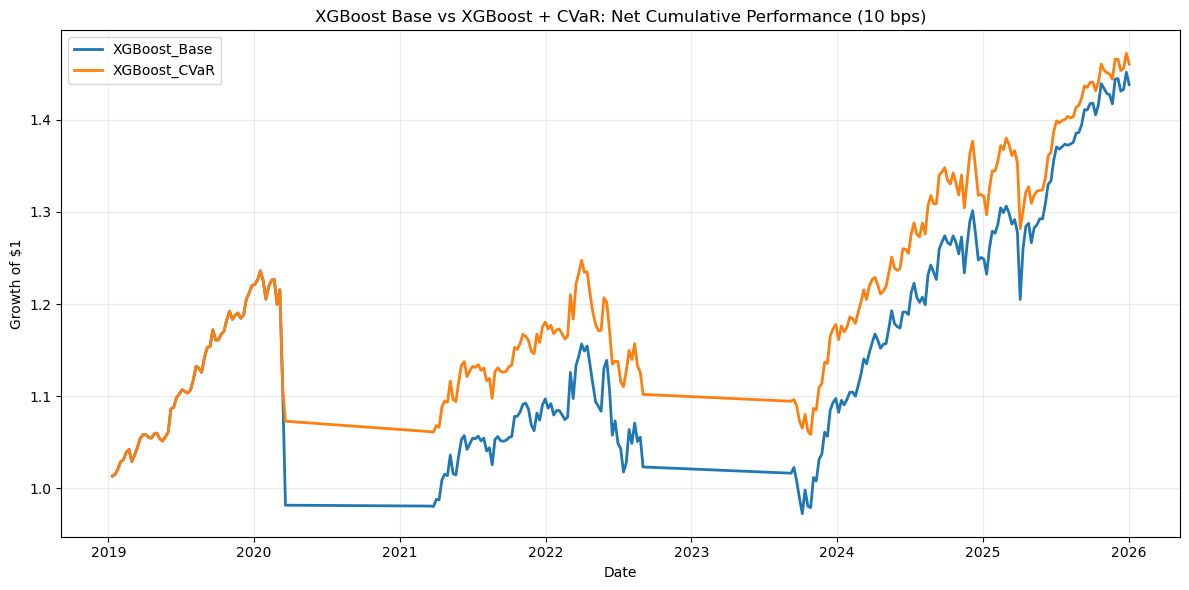

In [37]:
cumulative_net = (1 + net_returns_10bps).cumprod()

fig, ax = plt.subplots(figsize=(12, 6))
for name in cumulative_net.columns:
    ax.plot(
        cumulative_net.index,
        cumulative_net[name],
        label=name,
        linewidth=2.0
    )

ax.set_title("XGBoost Base vs XGBoost + CVaR: Net Cumulative Performance (10 bps)")
ax.set_ylabel("Growth of $1")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(
    BASE / "outputs" / "figures" / "xgb_base_vs_cvar_net_cumulative_10bps.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


## 20.2 Drawdown Comparison — 10 bps


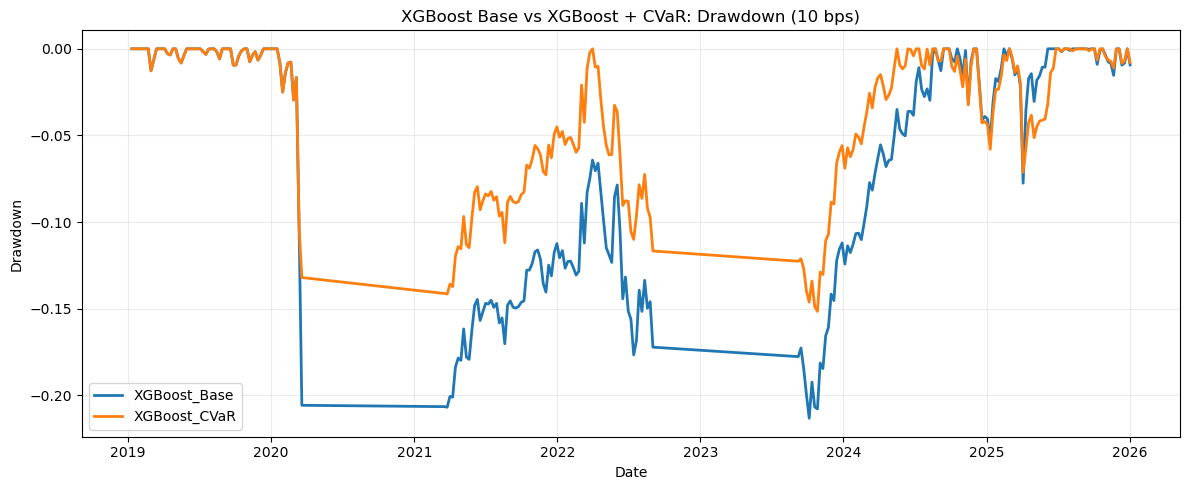

In [38]:
drawdown = cumulative_net / cumulative_net.cummax() - 1

fig, ax = plt.subplots(figsize=(12, 5))
for name in drawdown.columns:
    ax.plot(
        drawdown.index,
        drawdown[name],
        label=name,
        linewidth=2.0
    )

ax.set_title("XGBoost Base vs XGBoost + CVaR: Drawdown (10 bps)")
ax.set_ylabel("Drawdown")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(
    BASE / "outputs" / "figures" / "xgb_base_vs_cvar_drawdown_10bps.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


## 20.3 Weekly Turnover


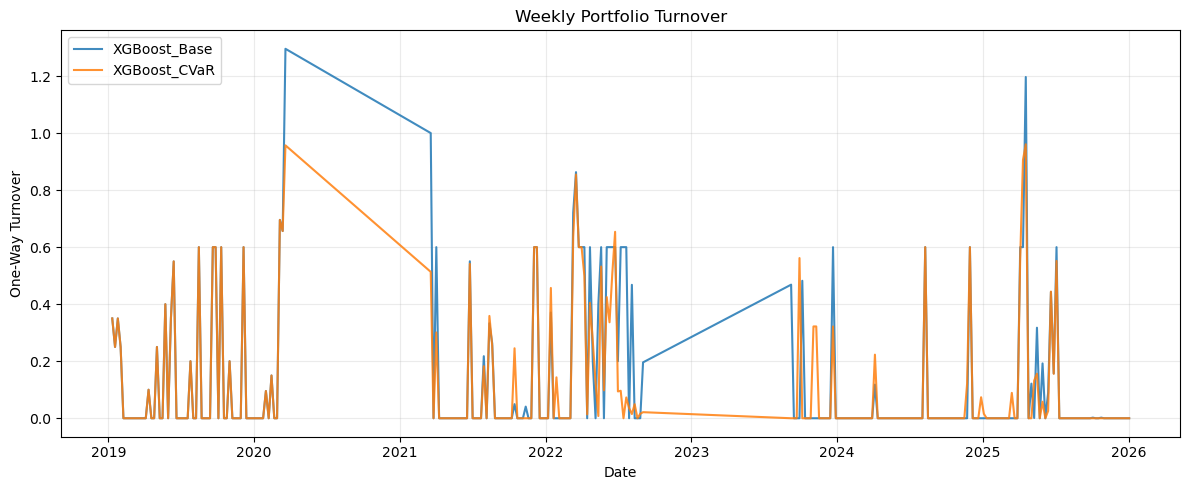

In [39]:
fig, ax = plt.subplots(figsize=(12, 5))

for name in turnover.columns:
    ax.plot(turnover.index, turnover[name], label=name, alpha=0.85)

ax.set_title("Weekly Portfolio Turnover")
ax.set_ylabel("One-Way Turnover")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(
    BASE / "outputs" / "figures" / "xgb_base_vs_cvar_turnover.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


## 20.4 CVaR Portfolio Historical Risk vs Fixed Constraint


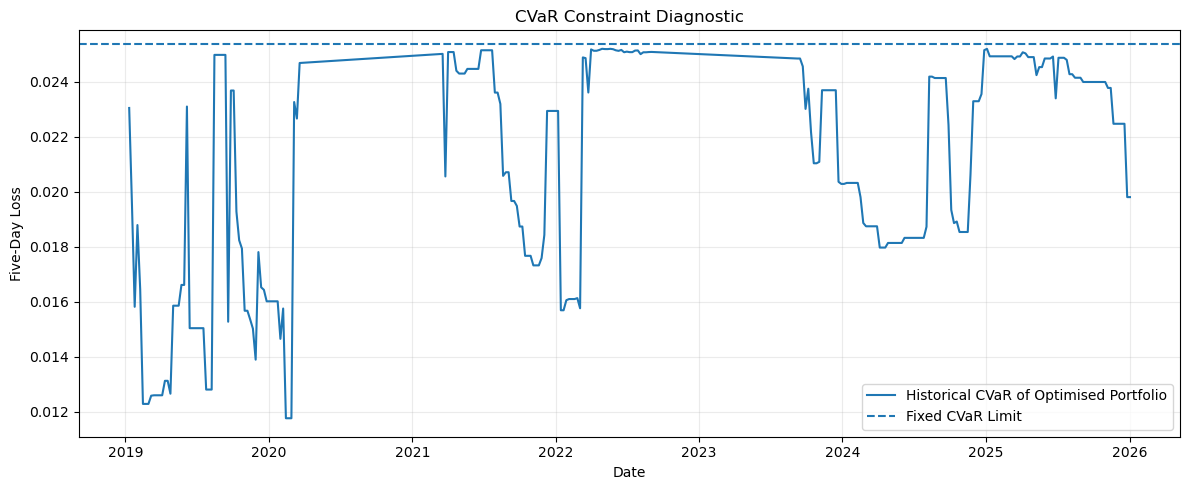

In [40]:
risk_check = optimisation_diagnostics.set_index("Return_Date")[
    ["CVaR_Limit", "CVaR_Portfolio_Historical_CVaR"]
].dropna()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    risk_check.index,
    risk_check["CVaR_Portfolio_Historical_CVaR"],
    label="Historical CVaR of Optimised Portfolio",
)
ax.axhline(
    CVAR_LIMIT,
    linestyle="--",
    label="Fixed CVaR Limit",
)

ax.set_title("CVaR Constraint Diagnostic")
ax.set_ylabel("Five-Day Loss")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(
    BASE / "outputs" / "figures" / "cvar_constraint_diagnostic.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# 21. Secondary 99% CVaR Diagnostic

The main experiment uses 95% CVaR. As a compact robustness check, the realised 99% CVaR of the final net return series is also reported.

This does not re-optimise the portfolio at 99%; it evaluates the severity of the more extreme realised tail.


In [41]:
secondary_tail_metrics = pd.DataFrame(index=net_returns_10bps.columns)

secondary_tail_metrics["Realized_CVaR_95"] = [
    realised_cvar(net_returns_10bps[c], 0.95)
    for c in net_returns_10bps.columns
]

secondary_tail_metrics["Realized_CVaR_99"] = [
    realised_cvar(net_returns_10bps[c], 0.99)
    for c in net_returns_10bps.columns
]

display(secondary_tail_metrics.round(4))


,Realized_CVaR_95,Realized_CVaR_99
XGBoost_Base,0.0392,0.0866
XGBoost_CVaR,0.0303,0.0576


# 22. Stress-Period Analysis

The capstone design highlights two economically important stress environments:

- the 2020 COVID-19 shock,
- the 2022 inflation / interest-rate shock.

The table below reports the same net performance metrics for these sub-periods.


In [42]:
stress_periods = {
    "COVID_2020": ("2020-01-01", "2020-12-31"),
    "Inflation_Rate_Shock_2022": ("2022-01-01", "2022-12-31"),
}

stress_rows = []

for period_name, (start, end) in stress_periods.items():
    subset = net_returns_10bps.loc[start:end]

    for portfolio in subset.columns:
        metrics = performance_metrics(subset[portfolio])
        row = metrics.to_dict()
        row.update({
            "Period": period_name,
            "Portfolio": portfolio,
        })
        stress_rows.append(row)

stress_metrics = pd.DataFrame(stress_rows).set_index(["Period", "Portfolio"])
display(stress_metrics.round(4))


Annualized_Return  Annualized_Volatility  Sharpe_Ratio  Sortino_Ratio  Maximum_Drawdown  Realized_CVaR_95
Period                    Portfolio                                                                                                              
COVID_2020                XGBoost_Base            -0.6101                 0.2965       -2.0580        -1.7631           -0.2058            0.1143
                          XGBoost_CVaR            -0.4272                 0.2041       -2.0928        -1.8634           -0.1320            0.0883
Inflation_Rate_Shock_2022 XGBoost_Base            -0.0984                 0.1489       -0.6608        -1.2480           -0.1201            0.0375
                          XGBoost_CVaR            -0.0971                 0.1175       -0.8261        -1.5463           -0.1167            0.0284

# 23. Save CVaR and Transaction-Cost Outputs


In [43]:
portfolio_weights.to_csv(
    BASE / "outputs" / "cvar" / "xgb_base_cvar_portfolio_weights.csv",
    index=False
)

optimisation_diagnostics.to_csv(
    BASE / "outputs" / "cvar" / "optimisation_diagnostics.csv",
    index=False
)

gross_returns.to_csv(
    BASE / "outputs" / "cvar" / "gross_weekly_returns.csv"
)

turnover.to_csv(
    BASE / "outputs" / "cvar" / "weekly_turnover.csv"
)

transaction_costs_10bps.to_csv(
    BASE / "outputs" / "cvar" / "transaction_costs_10bps.csv"
)

net_returns_10bps.to_csv(
    BASE / "outputs" / "cvar" / "net_weekly_returns_10bps.csv"
)

gross_metrics.to_csv(
    BASE / "outputs" / "cvar" / "gross_performance_metrics.csv"
)

net_metrics_10bps.to_csv(
    BASE / "outputs" / "cvar" / "net_performance_metrics_10bps.csv"
)

cost_sensitivity_metrics.to_csv(
    BASE / "outputs" / "cvar" / "transaction_cost_sensitivity_metrics.csv"
)

secondary_tail_metrics.to_csv(
    BASE / "outputs" / "cvar" / "secondary_tail_metrics.csv"
)

stress_metrics.to_csv(
    BASE / "outputs" / "cvar" / "stress_period_metrics.csv"
)


parameter_tuning.to_csv(
    BASE / "outputs" / "cvar" / "portfolio_parameter_tuning.csv",
    index=False
)

print("All CVaR and transaction-cost outputs saved.")


All CVaR and transaction-cost outputs saved.


# 24. Final Data and Output Checks


In [44]:
checks = pd.DataFrame({
    "Dataset": [
        "Adjusted Close",
        "Daily Returns",
        "5-Day Forward Returns",
        "Weekly Prices",
        "Weekly Returns",
        "XGBoost Forecasts",
        "Portfolio Weight Records",
        "Gross Portfolio Returns",
        "Turnover",
        "Net Returns at 10 bps",
        "Optimisation Diagnostics",
    ],
    "Rows": [
        len(prices_aligned),
        len(daily_returns),
        len(forward_5d_returns),
        len(weekly_prices),
        len(weekly_returns),
        len(xgb_forecasts),
        len(portfolio_weights),
        len(gross_returns),
        len(turnover),
        len(net_returns_10bps),
        len(optimisation_diagnostics),
    ]
})

display(checks)

print("\nWeight-sum checks:")
print("Base maximum deviation from 1:",
      (base_weights.sum(axis=1) - 1).abs().max())
print("CVaR maximum deviation from 1:",
      (cvar_weights.sum(axis=1) - 1).abs().max())

print("\nMaximum observed weights:")
print("Base:", base_weights.max().max())
print("CVaR:", cvar_weights.max().max())


,Dataset,Rows
0,Adjusted Close,4024
1,Daily Returns,4023
2,5-Day Forward Returns,4024
3,Weekly Prices,835
4,Weekly Returns,834
5,XGBoost Forecasts,365
6,Portfolio Weight Records,5016
7,Gross Portfolio Returns,262
8,Turnover,262
9,Net Returns at 10 bps,262



Weight-sum checks:
Base maximum deviation from 1: 2.9817004421062165e-10
CVaR maximum deviation from 1: 2.5013091597969606e-10

Maximum observed weights:
Base: 0.30000000196506027
CVaR: 0.3000000008680994


# 25. Interpretation

The main comparison is between the unconstrained XGBoost portfolio and the otherwise identical CVaR-constrained portfolio.

The key outputs are:

- realised 95% CVaR,
- maximum drawdown,
- annualised return and volatility,
- Sharpe and Sortino ratios,
- portfolio turnover,
- and performance after transaction costs.

The CVaR extension is useful if it reduces severe downside risk without causing a disproportionate deterioration in net risk-adjusted performance.


# 26. Files Produced

### Processed data
- `data/raw/yahoo_etf_raw.csv`
- `data/processed/adjusted_close.csv`
- `data/processed/volume.csv`
- `data/processed/daily_returns.csv`
- `data/processed/log_returns.csv`
- `data/processed/forward_5d_returns.csv`
- `data/processed/weekly_prices.csv`
- `data/processed/weekly_returns.csv`
- `data/processed/modelling_calendar.csv`

### Forecast outputs
- `outputs/cvar/xgb_validation_metrics.csv`
- `outputs/cvar/xgb_test_forecasts.csv`
- `outputs/cvar/xgb_test_forecast_metadata.csv`
- `outputs/cvar/xgb_test_forecast_metrics.csv`

### Portfolio / CVaR outputs
- `outputs/cvar/xgb_base_cvar_portfolio_weights.csv`
- `outputs/cvar/optimisation_diagnostics.csv`
- `outputs/cvar/gross_weekly_returns.csv`
- `outputs/cvar/weekly_turnover.csv`
- `outputs/cvar/transaction_costs_10bps.csv`
- `outputs/cvar/net_weekly_returns_10bps.csv`
- `outputs/cvar/gross_performance_metrics.csv`
- `outputs/cvar/net_performance_metrics_10bps.csv`
- `outputs/cvar/transaction_cost_sensitivity_metrics.csv`
- `outputs/cvar/secondary_tail_metrics.csv`
- `outputs/cvar/stress_period_metrics.csv`

### Figures
- `outputs/figures/xgb_base_vs_cvar_net_cumulative_10bps.png`
- `outputs/figures/xgb_base_vs_cvar_drawdown_10bps.png`
- `outputs/figures/xgb_base_vs_cvar_turnover.png`
- `outputs/figures/cvar_constraint_diagnostic.png`


# References

- Chen, T. and Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 785-794.
- Markowitz, H. (1952). *Portfolio Selection*. The Journal of Finance, 7(1), 77-91.
- Rockafellar, R. T. and Uryasev, S. (2000). *Optimization of Conditional Value-at-Risk*. The Journal of Risk, 2(3), 21-41.
